In [1]:
import json

import agama
import h5py
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import pandas as pd
from chainconsumer import Chain, ChainConsumer, PlotConfig
from numpyro.infer import MCMC, NUTS
from scipy.interpolate import interp1d

agama.setUnits(mass=1, length=1, velocity=1)
units = agama.getUnits()

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 10
MEDIUM_SIZE = 10
BIGGER_SIZE = 10

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [2]:
# references

# https://academic.oup.com/mnras/article/527/2/2624/7337353


In [3]:
sim_dir = "/Users/z5114326/Documents/simulations/"
# sim_dir = "/Volumes/Expansion/simulations/"

sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]
# sim_lst = ["m12i"]

sim_codes = sim_dir + "simulation_codes.json"
with open(sim_codes) as sim_json:
    sim_data = json.load(sim_json)

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

In [4]:
dat_dict = {
    sim: {
        "q": {"q16": None, "q50": None, "q84": None},
        "rho_data": {"rho_p16": None, "rho_p50": None, "rho_p84": None},
        "log_rho_sol": {"lower": None, "center": None, "upper": None},
        "alpha": {"lower": None, "center": None, "upper": None},
    }
    for sim in sim_lst
}

Rd_json = "../data/sim_data/Rd_dict.json"
with open(Rd_json, "r") as f:
    Rd_dict = json.load(f)

# Milky Way values from Ananke / JBH + G 16
Rd_mw = 2.6
Rsol_mw = 8.2  # kpc

# values for analysis
n_q_mc = 100
rbins = np.linspace(0, 15, 60)
rmid = 0.5 * (rbins[1:] + rbins[:-1])

halo_json = "../data/sim_data/halo_dict.json"
with open(halo_json, "r") as f:
    halo_dict = json.load(f)

fn0_json = "../data/mw_gcs/fno_mw_gcs.json"
with open(fn0_json, "r") as f:
    fn0_dict = json.load(f)

Text(0, 0.5, 'f$_{\\mathrm{N/O}}$')

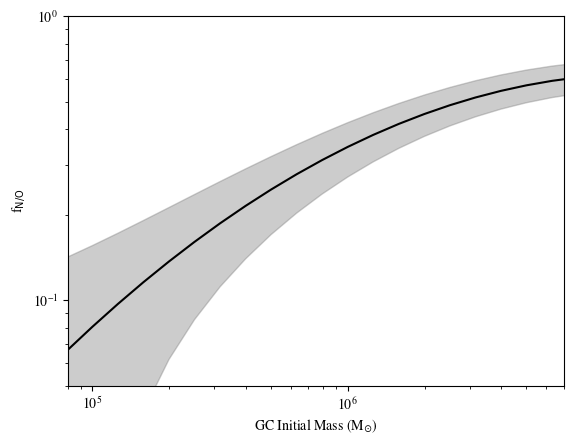

In [5]:
# Function from BK23

xlogfit = np.arange(4, 7.1, 0.1)
A = fn0_dict["A"]
B = fn0_dict["B"]
C = fn0_dict["C"]

ylogfit = A + B * xlogfit + C * xlogfit**2
yerr = fn0_dict["yerr"]

plt.plot(10**xlogfit, 10**ylogfit, c="k")
plt.xscale("log")
plt.yscale("log")

plt.xlim(8 * 10**4, 7 * 10**6)
plt.ylim(0.05, 1)

plt.fill_between(10**xlogfit, 10**ylogfit - yerr, 10**ylogfit + yerr, color="grey", alpha=0.4)

plt.xlabel(r"GC Initial Mass (M$_{\odot}$)")
plt.ylabel(r"f$_{\mathrm{N/O}}$")

# Milk Way Data

In [ ]:
# =====================================================
# Radius grid
# =====================================================

r_mw = np.linspace(1.5, 15.0, 1000)

# =====================================================
# Angular grids
# =====================================================

theta = np.linspace(0, np.pi, 2000)
sin_theta = np.sin(theta)
norm = np.trapezoid(sin_theta, theta)

phi = np.linspace(0, 2 * np.pi, 1000)

theta2d, phi2d = np.meshgrid(theta, phi, indexing="ij")

sin_t = np.sin(theta2d)
cos_t = np.cos(theta2d)

cos_p = np.cos(phi2d)
sin_p = np.sin(phi2d)

# =====================================================
# N-rich AXI model (UNCHANGED)
# =====================================================


def spherical_profile(r_mw, rho0, alpha, q):

    geom = np.sqrt(np.sin(theta) ** 2 + np.cos(theta) ** 2 / q**2)

    angular_factor = np.trapezoid(geom ** (-alpha) * sin_theta, theta) / norm

    return rho0 * angular_factor * (r_mw / Rsol_mw) ** (-alpha)


# =====================================================
# Halo TRI-CUT-DISC halo component
# =====================================================


def spherical_profile_triaxial(r_mw, rho0, alpha, p, q):

    geom = np.sqrt(sin_t**2 * cos_p**2 + sin_t**2 * sin_p**2 / p**2 + cos_t**2 / q**2)

    angular_factor = np.trapezoid(
        np.trapezoid(
            geom ** (-alpha) * sin_t,
            phi,
            axis=1,
        ),
        theta,
        axis=0,
    ) / (4.0 * np.pi)

    return rho0 * angular_factor * (r_mw / Rsol_mw) ** (-alpha)


# =====================================================
# Monte Carlo settings
# =====================================================

rng = np.random.default_rng(42)
Nmc = 200

# =====================================================
# N-rich parameters
# =====================================================

nr_alpha = 4.47
nr_alpha_low = 0.22
nr_alpha_upp = 0.23
nr_alpha_sigma = (nr_alpha_low + nr_alpha_upp) / 2

nr_q = 0.47
nr_q_low = 0.04
nr_q_upp = 0.05
nr_q_sigma = (nr_q_low + nr_q_upp) / 2

nr_rho0 = 3.1e-6 * 1e9
nr_rho0_low = 0.5e-6 * 1e9
nr_rho0_upp = 0.6e-6 * 1e9
nr_rho0_sigma = (nr_rho0_low + nr_rho0_upp) / 2

# =====================================================
# Halo parameters
# =====================================================

halo_alpha = 3.48
halo_alpha_low = 0.07
halo_alpha_upp = 0.05
halo_alpha_sigma = (halo_alpha_low + halo_alpha_upp) / 2

halo_p = 0.76
halo_p_low = 0.04
halo_p_upp = 0.03
halo_p_sigma = (halo_p_low + halo_p_upp) / 2

halo_q = 0.46
halo_q_low = 0.01
halo_q_upp = 0.01
halo_q_sigma = (halo_q_low + halo_q_upp) / 2

halo_beta = 0.01
halo_beta_low = 0.00
halo_beta_upp = 0.00
halo_beta_sigma = (halo_beta_low + halo_beta_upp) / 2

halo_rho0 = 1.3e-4 * 1e9
halo_rho0_low = 0.2e-4 * 1e9
halo_rho0_upp = 0.1e-4 * 1e9
halo_rho0_sigma = (halo_rho0_low + halo_rho0_upp) / 2

# =====================================================
# Generate N-rich profiles
# =====================================================

nr_profiles = np.empty((Nmc, len(r_mw)))

for i in range(Nmc):
    alpha = rng.normal(nr_alpha, nr_alpha_sigma)
    q = rng.normal(nr_q, nr_q_sigma)
    rho0 = rng.normal(nr_rho0, nr_rho0_sigma)

    q = max(q, 0.1)
    rho0 = max(rho0, 1.0)

    nr_profiles[i] = spherical_profile(r_mw, rho0, alpha, q)

mw_nr50 = np.percentile(nr_profiles, 50, axis=0)
mw_nr16 = np.percentile(nr_profiles, 16, axis=0)
mw_nr84 = np.percentile(nr_profiles, 84, axis=0)

# =====================================================
# Generate Halo profiles
# =====================================================

halo_profiles = np.empty((Nmc, len(r_mw)))

for i in range(Nmc):
    alpha = rng.normal(halo_alpha, halo_alpha_sigma)
    p = rng.normal(halo_p, halo_p_sigma)
    q = rng.normal(halo_q, halo_q_sigma)
    beta = rng.normal(halo_beta, halo_beta_sigma)
    rho0 = rng.normal(halo_rho0, halo_rho0_sigma)

    p = max(p, 0.1)
    q = max(q, 0.1)
    beta = max(beta, 0.0)
    rho0 = max(rho0, 1.0)

    halo_profiles[i] = spherical_profile_triaxial(r_mw, rho0, alpha, p, q)

mw_halo50 = np.percentile(halo_profiles, 50, axis=0)
mw_halo16 = np.percentile(halo_profiles, 16, axis=0)
mw_halo84 = np.percentile(halo_profiles, 84, axis=0)

# Simulation Data

In [ ]:
# Functions ##################################################################################################


def n_rich_model(r, Rsol, logrho_obs=None, sigma=None):

    logrho_sol = numpyro.sample(
        "logrho_sol",
        dist.Uniform(-5.0, 12.0),
    )

    alpha = numpyro.sample(
        "alpha",
        dist.Uniform(0.0, 10.0),
    )

    mu = logrho_sol - alpha * jnp.log10(r / Rsol)

    numpyro.sample(
        "obs",
        dist.Normal(mu, sigma),
        obs=logrho_obs,
    )

In [ ]:
# Get q_vals (flattening) for N-rich fittening

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    q_iter_mc = []
    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        # mass data
        log_mfor = src_dat["logm_tfor"][()]
        mfor = 10**log_mfor
        mfor_ev = 0.55 * mfor

        mz0 = np.array([0 if m0 == -1 else 10**m0 for m0 in src_dat["logm_tz0"][()]])

        mdifs = mfor_ev - mz0

        # BK23 relation
        log_fNO_mean = A + B * log_mfor + C * log_mfor**2

        # positions
        xyz = src_dat["pxyz_snap600"][()]
        x = xyz[:, 0]
        y = xyz[:, 1]
        z0 = xyz[:, 2]

        q_mc = np.zeros(n_q_mc)
        for i in range(n_q_mc):
            log_fNO_draw = np.random.normal(log_fNO_mean, yerr)
            fNO_draw = 10**log_fNO_draw

            mfN0_draw = mdifs * fNO_draw
            good = mfN0_draw > 0

            R = np.sqrt(x[good] ** 2 + y[good] ** 2)
            z = z0[good]
            r3d = np.sqrt(R**2 + z**2)

            weights = mfN0_draw[good]
            mask = (r3d > 1.5) & (r3d < 15.0)

            if np.any(mask):
                q_mc[i] = np.sqrt(
                    np.average(z[mask] ** 2, weights=weights[mask])
                    / np.average(R[mask] ** 2, weights=weights[mask])
                )
            else:
                q_mc[i] = np.nan
        q_mc = q_mc[np.isfinite(q_mc)]

        if len(q_mc) > 1:
            q_iter_mc.append(q_mc)

    # Build the final distribution by combining each iteration
    # from every equally-valid realization
    q_post = np.concatenate(q_iter_mc)
    q16, q50, q84 = np.percentile(q_post, [16, 50, 84])

    dat_dict[sim]["q"]["q16"] = q16
    dat_dict[sim]["q"]["q50"] = q50
    dat_dict[sim]["q"]["q84"] = q84
    dat_dict[sim]["q"]["q_post"] = q_post

fig, axs = plt.subplots(2, 3, figsize=(14, 8))
axs = axs.flatten()
plt.subplots_adjust(wspace=0.05, hspace=0.05)

for (i, ax), sim in zip(enumerate(axs), sim_lst):
    q_post = dat_dict[sim]["q"]["q_post"]

    q16 = dat_dict[sim]["q"]["q16"]
    q50 = dat_dict[sim]["q"]["q50"]
    q84 = dat_dict[sim]["q"]["q84"]

    ax.hist(
        q_post,
        bins=30,
        density=True,
        color=sim_colors[sim],
        alpha=0.5,
    )

    ax.axvline(q50, color="k", lw=2)
    ax.axvline(q16, color="r", ls="--", lw=2)
    ax.axvline(q84, color="r", ls="--", lw=2)

    simtext = (
        rf"$\mathrm{{{sim}}}$"
        "\n"
        rf"$q={q50:.3f}_{{-{q50 - q16:.3f}}}^{{+{q84 - q50:.3f}}}$"
    )

    if sim in ["m12c", "m12m"]:
        tx = 0.65
    else:
        tx = 0.05

    ax.text(
        tx,
        0.85,
        simtext,
        transform=ax.transAxes,
        fontsize=10,
        ha="left",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            boxstyle="round,pad=0.3",
        ),
    )

    if i not in [0, 1]:
        ax.set_xlabel(r"$q$")
    else:
        ax.set_xticklabels([])
    if i in [0, 3]:
        ax.set_ylabel("PDF")
    else:
        ax.set_yticklabels([])

    ax.set_xlim(0.32, 0.72)
    ax.set_ylim(0, 35)

axs[-1].axis("off")

q_vals = "../data/figures/n_rich_fitting/q_fitting.pdf"
fig.savefig(q_vals)

plt.show()

In [ ]:
# Get N-rich densitites ######################################################################################

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    # posterior on q from previous calculation
    q_post = dat_dict[sim]["q"]["q_post"]

    rho_all = []
    for it_id in ghost_data:
        src_dat = ghost_data[it_id]["source"]

        log_mfor = src_dat["logm_tfor"][()]
        mfor = 10**log_mfor
        mfor_ev = 0.55 * mfor
        mz0 = np.array([0 if m0 == -1 else 10**m0 for m0 in src_dat["logm_tz0"][()]])
        mdifs = mfor_ev - mz0

        xyz = src_dat["pxyz_snap600"][()]
        x = xyz[:, 0]
        y = xyz[:, 1]
        z = xyz[:, 2]

        R = np.sqrt(x**2 + y**2)

        log_fNO_mean = A + B * log_mfor + C * log_mfor**2
        q_draw = dat_dict[sim]["q"]["q50"]

        for _ in range(n_q_mc):
            # draw q from the previously-computed q posterior
            # draw fNO
            log_fNO_draw = np.random.normal(log_fNO_mean, yerr)
            fNO_draw = 10**log_fNO_draw
            mfN0_draw = mdifs * fNO_draw

            # ellipsoidal radius
            mell = np.sqrt(R**2 + (z / q_draw) ** 2)
            mass_shell, _ = np.histogram(mell, bins=rbins, weights=mfN0_draw)

            # ellipsoidal shell volume
            vol_shell = (4.0 / 3.0) * np.pi * q_draw * (rbins[1:] ** 3 - rbins[:-1] ** 3)

            rho_draw = mass_shell / vol_shell
            rho_all.append(rho_draw)

    rho_all = np.asarray(rho_all)

    rho_p16 = np.percentile(rho_all, 16, axis=0)
    rho_p50 = np.percentile(rho_all, 50, axis=0)
    rho_p84 = np.percentile(rho_all, 84, axis=0)

    dat_dict[sim]["rho_data"]["rho_p16"] = rho_p16
    dat_dict[sim]["rho_data"]["rho_p50"] = rho_p50
    dat_dict[sim]["rho_data"]["rho_p84"] = rho_p84


# Get N-rich best fit model ##################################################################################

plot_corners = True
mask_r = True  # match the Horta's work and only fit to data outside of inner kpc.

if mask_r:
    rmsk = rmid > 1
else:
    rmsk = np.ones(len(rmid), dtype=bool)

for sim in sim_lst:
    rho50 = dat_dict[sim]["rho_data"]["rho_p50"][rmsk]
    rho16 = dat_dict[sim]["rho_data"]["rho_p16"][rmsk]
    rho84 = dat_dict[sim]["rho_data"]["rho_p84"][rmsk]

    good = (
        np.isfinite(rho50) & np.isfinite(rho16) & np.isfinite(rho84) & (rho50 > 0) & (rho16 > 0) & (rho84 > 0)
    )

    r = rmid[rmsk][good]
    logrho = np.log10(rho50[good])

    sigma_logrho = (np.log10(rho84[good]) - np.log10(rho16[good])) / 2.0

    nuts_kernel = NUTS(n_rich_model)
    mcmc = MCMC(nuts_kernel, num_warmup=1000, num_samples=10000)

    rng_key = jax.random.PRNGKey(0)

    Rsol = Rsol_mw * Rd_dict[sim] / Rd_mw

    mcmc.run(
        rng_key,
        r=jnp.asarray(r),
        Rsol=Rsol,
        logrho_obs=jnp.asarray(logrho),
        sigma=jnp.asarray(sigma_logrho),
    )

    samples = mcmc.get_samples()

    df = pd.DataFrame(
        {
            "log_rho_sol": samples["logrho_sol"],
            "alpha": samples["alpha"],
        }
    )

    CC = ChainConsumer()
    CC.add_chain(Chain(samples=df, name=sim))

    summ = C.analysis.get_summary()[sim]

    dat_dict[sim]["log_rho_sol"]["lower"] = np.round(summ["log_rho_sol"].lower, 3)
    dat_dict[sim]["log_rho_sol"]["center"] = np.round(summ["log_rho_sol"].center, 3)
    dat_dict[sim]["log_rho_sol"]["upper"] = np.round(summ["log_rho_sol"].upper, 3)

    dat_dict[sim]["alpha"]["lower"] = np.round(summ["alpha"].lower, 3)
    dat_dict[sim]["alpha"]["center"] = np.round(summ["alpha"].center, 3)
    dat_dict[sim]["alpha"]["upper"] = np.round(summ["alpha"].upper, 3)

    if plot_corners:
        plot_df = df.rename(
            columns={
                "log_rho_sol": r"$\log_{10}\rho_{\odot,\rm equiv}$",
                "alpha": r"$\alpha$",
            }
        )

        CC = ChainConsumer()
        CC.add_chain(Chain(samples=plot_df, name=sim))
        CC.set_plot_config(
            PlotConfig(
                diagonal_tick_labels=True,
                shade=True,
                shade_alpha=0.4,
                sigma2d=True,
                flip=False,
            )
        )
        fig = CC.plotter.plot(figsize=(5, 5))

        fitting = "../data/figures/n_rich_fitting/" + sim + "_n_rich_fitting.pdf"
        fig.savefig(fitting)

In [ ]:
plot_text = True

if plot_text:
    sim_x = 0.25
    sim_y = 0.90
    save_name = "../data/figures/n_rich_fitting/density_plots_text.pdf"
    leg_loc = "lower right"
else:
    sim_x = 0.10
    sim_y = 0.05
    save_name = "../data/figures/n_rich_fitting/density_plots.pdf"
    leg_loc = "upper right"


fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
plt.subplots_adjust(wspace=0.05, hspace=0.05)

for i, ax in enumerate(axs.flatten()):
    if i > 4:
        continue
    sim = sim_lst[i]

    ax.plot(rmid, dat_dict[sim]["rho_data"]["rho_p50"], color=sim_colors[sim], lw=1, label=sim + r" N-rich")
    ax.fill_between(
        rmid,
        dat_dict[sim]["rho_data"]["rho_p16"],
        dat_dict[sim]["rho_data"]["rho_p84"],
        color=sim_colors[sim],
        alpha=0.3,
    )

    Rsol = Rsol_mw * Rd_dict[sim] / Rd_mw

    # N-Rich information #######################################################################################

    best_fit = 10 ** dat_dict[sim]["log_rho_sol"]["center"] * (rmid / Rsol) ** (
        -dat_dict[sim]["alpha"]["center"]
    )
    ax.plot(rmid, best_fit, color=sim_colors[sim], lw=2, ls="--")

    ax.set_yscale("log")

    ax.set_xlim(0, 15)
    ax.set_xticks([0, 2, 4, 6, 8, 10, 12, 14])

    ax.set_ylim(0.8 * 10**1, 2 * 10**9)

    if i < 3:
        ax.set_xticklabels([])
    else:
        ax.set_xlabel("r [kpc]")

    if i not in [0, 3]:
        ax.set_yticklabels([])
    else:
        ax.set_ylabel(r"$\rho_\star\ [{\rm M_\odot\,kpc^{-3}}]$")

    ax.text(
        sim_x,
        sim_y,
        sim,
        transform=ax.transAxes,
        fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
        ha="center",
    )

    a_low = dat_dict[sim]["alpha"]["center"] - dat_dict[sim]["alpha"]["lower"]
    a_upp = dat_dict[sim]["alpha"]["upper"] - dat_dict[sim]["alpha"]["center"]

    rho0_low = dat_dict[sim]["log_rho_sol"]["center"] - dat_dict[sim]["log_rho_sol"]["lower"]
    rho0_upp = dat_dict[sim]["log_rho_sol"]["upper"] - dat_dict[sim]["log_rho_sol"]["center"]

    qc = dat_dict[sim]["q"]["q50"]
    ql = qc - dat_dict[sim]["q"]["q16"]
    qu = dat_dict[sim]["q"]["q84"] - qc

    if plot_text:
        nrich_text = ax.text(
            0.025,
            0.05,
            (
                rf"$q={qc:.2f}^{{+{qu:.2f}}}_{{-{ql:.2f}}}$"
                "\n"
                rf"$\alpha={dat_dict[sim]['alpha']['center']:.2f}^{{+{a_upp:.2f}}}_{{-{a_low:.2f}}}$"
                "\n"
                rf"$\log\rho_\odot={dat_dict[sim]['log_rho_sol']['center']:.2f}^{{+{rho0_upp:.2f}}}_{{-{rho0_low:.2f}}}$"
                "\n"
                rf"R$_\odot$= {Rsol:.1f} kpc"
            ),
            ha="left",
            transform=ax.transAxes,
            fontsize=9,
        )
        nrich_text.set_color(sim_colors[sim])

    # Halo information #######################################################################################

    rh = np.array(halo_dict[sim]["rmid"])
    rho_halo = np.array(halo_dict[sim]["rho_halo"])

    alpha_halo = halo_dict[sim]["alpha"]["center"]
    beta_halo = halo_dict[sim]["beta"]["center"]
    log_rho_sol_halo = halo_dict[sim]["log_rho_sol"]["center"]

    log_rho_fit = log_rho_sol_halo - alpha_halo * np.log10(rh / Rsol) - beta_halo * rh / np.log(10.0)
    rho_fit = 10**log_rho_fit

    ax.plot(rh, rho_halo, color="k", lw=1, label=sim + r" Halo")
    ax.plot(rh, rho_fit, color="k", lw=2, ls="--")

    qh = np.round(halo_dict[sim]["q"], 2)
    ph = np.round(halo_dict[sim]["p"], 2)

    ac = np.round(halo_dict[sim]["alpha"]["center"], 2)
    al = ac - np.round(halo_dict[sim]["alpha"]["lower"], 2)
    au = np.round(halo_dict[sim]["alpha"]["upper"], 2) - ac

    bc = np.round(halo_dict[sim]["beta"]["center"], 2)
    bl = bc - np.round(halo_dict[sim]["beta"]["lower"], 2)
    bu = np.round(halo_dict[sim]["beta"]["upper"], 2) - bc

    roc = np.round(halo_dict[sim]["log_rho_sol"]["center"], 2)
    rol = roc - np.round(halo_dict[sim]["log_rho_sol"]["lower"], 2)
    rou = np.round(halo_dict[sim]["log_rho_sol"]["upper"], 2) - roc

    if plot_text:
        ax.text(
            0.97,
            0.62,
            (
                rf"$q={qh}$"
                "\n"
                rf"$p={ph}$"
                "\n"
                rf"$\alpha={ac:.2f}^{{+{au:.2f}}}_{{-{al:.2f}}}$"
                "\n"
                rf"$\beta={bc:.2f}^{{+{bu:.2f}}}_{{-{bl:.2f}}}$"
                "\n"
                rf"$\log\rho_\odot={roc:.2f}^{{+{rou:.2f}}}_{{-{rol:.2f}}}$"
            ),
            ha="right",
            transform=ax.transAxes,
            fontsize=9,
        )

    if not plot_text:
        # add milky way data to each panel
        # ax.plot(r_mw, mw_nr50, color="#E29B20", lw=1, label="MW N-rich", ls="dotted")
        # ax.plot(r_mw, mw_halo50, color="k", lw=1, label="MW Halo", ls="dotted")

        ax.plot(r_mw, mw_nr50, color="#E29B20", lw=1, ls="dotted")
        ax.plot(r_mw, mw_halo50, color="k", lw=1, ls="dotted")

    ax.legend(loc=leg_loc)


ax = axs[1, 2]

solid = r_mw <= 10
dashed = r_mw > 10

# N-rich uncertainty
ax.fill_between(r_mw, mw_nr16, mw_nr84, color="#E29B20", alpha=0.25, linewidth=0)

# N-rich line
ax.plot(r_mw[solid], mw_nr50[solid], color="#E29B20", lw=2, label="N-rich")

ax.plot(r_mw[dashed], mw_nr50[dashed], "--", color="#E29B20", lw=2)

# Halo uncertainty
ax.fill_between(r_mw, mw_halo16, mw_halo84, color="lightgray", alpha=1.0, linewidth=0)

# Halo line
ax.plot(r_mw[solid], mw_halo50[solid], color="black", lw=2, label="Halo")

ax.plot(r_mw[dashed], mw_halo50[dashed], "--", color="black", lw=2)

# Axes
ax.set_yscale("log")

ax.set_xlim(0, 15)
ax.set_xticks([0, 2, 4, 6, 8, 10, 12, 14])

ax.set_ylim(0.8 * 10**1, 2 * 10**9)
ax.set_yticklabels([])

ax.set_xlabel("r [kpc]")

ax.legend(loc=leg_loc, fontsize=10)

ax.text(
    sim_x + 0.05,
    sim_y,
    "Milky Way",
    transform=ax.transAxes,
    fontsize=10,
    bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
    ha="center",
)

nr_rho0_tx = np.log10(nr_rho0)
nr_rho0_low_tx = nr_rho0_tx - np.log10(nr_rho0 - nr_rho0_low)
nr_rho0_upp_tx = np.log10(nr_rho0 + nr_rho0_upp) - nr_rho0_tx

if plot_text:
    mw_nrich_text = ax.text(
        0.025,
        0.05,
        (
            rf"$q={nr_q:.2f}^{{+{nr_q_upp:.2f}}}_{{-{nr_q_low:.2f}}}$"
            "\n"
            rf"$\alpha={nr_alpha:.2f}^{{+{nr_alpha_upp:.2f}}}_{{-{nr_alpha_low:.2f}}}$"
            "\n"
            rf"$\log\rho_\odot={nr_rho0_tx:.2f}^{{+{nr_rho0_upp_tx:.2f}}}_{{-{nr_rho0_upp_tx:.2f}}}$"
            "\n"
            rf"R$_\odot$= {Rsol_mw:.1f} kpc"
        ),
        ha="left",
        transform=ax.transAxes,
        fontsize=9,
    )
    mw_nrich_text.set_color("#E29B20")

halo_rho0_tx = np.log10(halo_rho0)
halo_rho0_low_tx = halo_rho0_tx - np.log10(halo_rho0 - halo_rho0_low)
halo_rho0_upp_tx = np.log10(halo_rho0 + halo_rho0_upp) - halo_rho0_tx

if plot_text:
    ax.text(
        0.97,
        0.60,
        (
            rf"$q={halo_q:.2f}^{{+{halo_q_upp:.2f}}}_{{-{halo_q_low:.2f}}}$"
            "\n"
            rf"$p={halo_p:.2f}^{{+{halo_p_upp:.2f}}}_{{-{halo_p_low:.2f}}}$"
            "\n"
            rf"$\alpha={halo_alpha:.2f}^{{+{halo_alpha_upp:.2f}}}_{{-{halo_alpha_low:.2f}}}$"
            "\n"
            rf"$\beta={halo_beta:.2f}^{{+{halo_beta_upp:.2f}}}_{{-{halo_beta_low:.2f}}}$"
            "\n"
            rf"$\log\rho_\odot={halo_rho0_tx:.2f}^{{+{halo_rho0_upp_tx:.2f}}}_{{-{halo_rho0_low_tx:.2f}}}$"
        ),
        ha="right",
        transform=ax.transAxes,
        fontsize=9,
    )


fig.savefig(save_name)
plt.show()

In [ ]:
def halo_profile(r, log_rho_sol, alpha, beta):
    log_rho = log_rho_sol - alpha * np.log10(r / Rsol) - beta * r / np.log(10.0)
    return 10**log_rho


def zeta_fitting(sim, dat_dict, Rsol, rh, rmid, rmin=0):
    rhmsk = rh > rmin
    rmmsk = rmid > rmin

    rh = np.array(rh)
    rmid = np.array(rmid)

    # ---------------------------
    # NR fit
    # ---------------------------
    nr_center = 10 ** dat_dict[sim]["log_rho_sol"]["center"] * (rmid[rmmsk] / Rsol) ** (
        -dat_dict[sim]["alpha"]["center"]
    )

    nr_lower = 10 ** dat_dict[sim]["log_rho_sol"]["lower"] * (rmid[rmmsk] / Rsol) ** (
        -dat_dict[sim]["alpha"]["lower"]
    )

    nr_upper = 10 ** dat_dict[sim]["log_rho_sol"]["upper"] * (rmid[rmmsk] / Rsol) ** (
        -dat_dict[sim]["alpha"]["upper"]
    )

    # Halo fit on halo grid
    halo_center = halo_profile(
        rh[rhmsk],
        halo_dict[sim]["log_rho_sol"]["center"],
        halo_dict[sim]["alpha"]["center"],
        halo_dict[sim]["beta"]["center"],
    )

    halo_lower = halo_profile(
        rh[rhmsk],
        halo_dict[sim]["log_rho_sol"]["lower"],
        halo_dict[sim]["alpha"]["lower"],
        halo_dict[sim]["beta"]["lower"],
    )

    halo_upper = halo_profile(
        rh[rhmsk],
        halo_dict[sim]["log_rho_sol"]["upper"],
        halo_dict[sim]["alpha"]["upper"],
        halo_dict[sim]["beta"]["upper"],
    )

    # ---------------------------
    # Interpolate halo fit onto rmid
    # (log-space interpolation)
    # ---------------------------
    halo_center_on_nr = 10 ** np.interp(rmid[rmmsk], rh[rhmsk], np.log10(halo_center))

    halo_lower_on_nr = 10 ** np.interp(rmid[rmmsk], rh[rhmsk], np.log10(halo_lower))

    halo_upper_on_nr = 10 ** np.interp(rmid[rmmsk], rh[rhmsk], np.log10(halo_upper))

    # ---------------------------
    # Ratio (%)
    # ---------------------------
    zeta_center = 100.0 * nr_center / halo_center_on_nr
    zeta_lower = 100.0 * nr_lower / halo_lower_on_nr
    zeta_upper = 100.0 * nr_upper / halo_upper_on_nr

    return zeta_center, zeta_lower, zeta_upper


In [ ]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
plt.subplots_adjust(wspace=0.05, hspace=0.05)

# Simulations ################################################################################################

for i, ax in enumerate(axs.flatten()):
    if i > 4:
        continue
    sim = sim_lst[i]

    Rsol = Rsol_mw * Rd_dict[sim] / Rd_mw

    # Model #####################################
    rmin = 1.5
    zeta_center, zeta_lower, zeta_upper = zeta_fitting(sim, dat_dict, Rsol, rh, rmid, rmin=rmin)

    rmmsk = rmid > rmin
    ax.plot(rmid[rmmsk], zeta_center, lw=2, label="Model Fit", color="k", ls="--")
    ax.fill_between(rmid[rmmsk], zeta_lower, zeta_upper, alpha=1, color="lightgray")

    # Data ######################################
    rh = np.asarray(halo_dict[sim]["rmid"])
    rho_halo = np.asarray(halo_dict[sim]["rho_halo"])

    rmid = np.asarray(rmid)
    rho_nr = np.asarray(dat_dict[sim]["rho_data"]["rho_p50"])
    rho_nr_lo = np.asarray(dat_dict[sim]["rho_data"]["rho_p16"])
    rho_nr_hi = np.asarray(dat_dict[sim]["rho_data"]["rho_p84"])

    # Common radial range
    msk = rmid > 0
    rho_halo_on_nr = 10 ** np.interp(rmid[msk], rh, np.log10(rho_halo))

    zeta_data = 100.0 * rho_nr[msk] / rho_halo_on_nr
    zeta_data_lo = 100.0 * rho_nr_lo[msk] / rho_halo_on_nr
    zeta_data_hi = 100.0 * rho_nr_hi[msk] / rho_halo_on_nr

    # Plot
    ax.plot(rmid[msk], zeta_data, color=sim_colors[sim], lw=2, label="Data")
    ax.fill_between(rmid[msk], zeta_data_lo, zeta_data_hi, color=sim_colors[sim], alpha=0.3)

    ax.text(
        0.85,
        0.90,
        sim,
        transform=ax.transAxes,
        fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
        ha="center",
    )

    ax.set_xlim(0, 15)
    ax.set_ylim(0, 5)

    ax.legend(loc="upper left")

    if i < 3:
        ax.set_xticklabels([])
    else:
        ax.set_xlabel("r [kpc]")

    if i in [0, 3]:
        ax.set_ylabel(r"$\zeta$ [%]")

# Milky Way ##################################################################################################

zeta_profiles = 100.0 * nr_profiles / halo_profiles

zeta50 = np.percentile(zeta_profiles, 50, axis=0)
zeta16 = np.percentile(zeta_profiles, 16, axis=0)
zeta84 = np.percentile(zeta_profiles, 84, axis=0)

ax = axs[1, 2]

# uncertainty region
ax.fill_between(r_mw, zeta16, zeta84, color="lightgray", lw=0)

# solid line up to 10 kpc
mask_solid = r_mw <= 10

ax.plot(r_mw[mask_solid], zeta50[mask_solid], color="black", lw=2)

# dashed line beyond 10 kpc
mask_dash = r_mw >= 10

ax.plot(r_mw[mask_dash], zeta50[mask_dash], color="black", lw=2, ls="--")

ax.set_xlim(0, 15)
ax.set_ylim(0, 25)

# ax.set_xlabel("r [kpc]")
# ax.set_ylabel(r"$\zeta$ [%]")

ax.set_xlabel("r [kpc]")

ax.text(
    0.85,
    0.90,
    "Milky Way",
    transform=ax.transAxes,
    fontsize=10,
    bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
    ha="center",
)

plt.tight_layout()

# ax.legend(loc="upper left")
save_name = "../data/figures/n_rich_fitting/ratio_plots.pdf"
fig.savefig(save_name)